In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from data import load_digits_dataset

from visualization import TrainingPlots, EvaluationPlots

from number_classifier import NumberClassifier

c:\Users\User\Documents\projects\NumberClassifier\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
X_train, X_test, y_train, y_test = load_digits_dataset()

In [3]:
epochs = 10000
batch_size = 32

loss_history = []
accuracy_history = []

In [4]:
input_size = X_train.shape[1]

In [5]:
model = NumberClassifier(input_size, 32, 20, 10)

In [6]:
with tqdm(range(epochs), desc="Training", unit="epoch") as pbar:
    for epoch in pbar:

        # Shuffle dataset at the beginning of each epoch
        indices = np.random.permutation(len(X_train))
    
        X_shuffled = X_train[indices]
        y_shuffled = y_train[indices]
    
        epoch_loss = 0
        epoch_accuracy = 0
    
        for start in range(0, len(X_shuffled), batch_size):
            end = start + batch_size
    
            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]
    
            loss, accuracy = model.forward(X_batch, y_batch)
    
            model.backward(X_batch, y_batch)
    
            epoch_loss += loss * len(X_batch)
            epoch_accuracy += accuracy * len(X_batch)
    
        # Average metrics across all training samples
        epoch_loss /= len(X_train)
        epoch_accuracy /= len(X_train)
    
        # Store metrics
        loss_history.append(epoch_loss)
        accuracy_history.append(epoch_accuracy)

        pbar.set_postfix({
            "Loss": f"{epoch_loss:.4f}",
            "Accuracy": f"{epoch_accuracy * 100:.2f}%"
        })
        

Training: 100%|██████████| 10000/10000 [01:07<00:00, 147.87epoch/s, Loss=0.0002, Accuracy=100.00%]


In [7]:
# Predict using the test dataset
loss, accuracy, predictions, confidence = model.predict(X_test, y_test)

EvaluationPlots.classification_report(y_test, predictions)
EvaluationPlots.confusion_matrix(y_test, predictions)

In [8]:
TrainingPlots.plot_loss(loss_history)
TrainingPlots.plot_accuracy(accuracy_history)

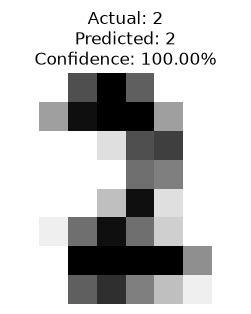

Loss: 0.0000
Correct: True


In [9]:
target = 15

# Select one test image and its label
X = X_test[target].reshape(1, -1)
y = y_test[target].reshape(1,)

loss, accuracy, prediction, confidence = model.predict(X, y) 

# Display test image
plt.figure(figsize=(3, 3))

plt.imshow(
    X_test[target].reshape(8, 8),
    cmap=plt.cm.gray_r
)

plt.title(
    f"Actual: {y[0]}\n"
    f"Predicted: {prediction[0]}\n"
    f"Confidence: {confidence[0]:.2f}%"
)

plt.axis("off")
plt.show()

print(f"Loss: {loss:.4f}")
print(f"Correct: {prediction[0] == y[0]}")

In [10]:
model.save()

Model saved to models\number_classifier.npz
